# exploration traindataset 

In [2]:
# libraries
import plotly.express as px
import matplotlib.pyplot as plt
import pandas as pd
# global variables
CORPUS_PATH = "../corpora-collection/sunset-corpus/src/normalized/"

In [6]:
df = pd.read_csv("src/city_country_metadata.tsv", sep="\t")
df.columns

Index(['ID', 'filename', 'title', 'author', 'gnd', 'birthYear', 'deathYear',
       'gender', 'source', 'pubYear', 'label', 'Source_Genre', 'textClass',
       'genre'],
      dtype='str')

In [7]:
len(df)

156

In [8]:
df.gender.value_counts()

gender
männlich    142
weiblich     14
Name: count, dtype: int64

In [40]:
df.loc[df.textClass=="Urban"].gender.value_counts()

gender
männlich    53
weiblich     3
Name: count, dtype: int64

In [16]:
for subset in df.textClass.unique():
    sliceDf = df.loc[df.textClass==subset]

    token_count = 0

    for file in sliceDf.filename:
        with open(CORPUS_PATH + file) as f:
            text = f.read()
        token_count = token_count + len(text.split())

    print(subset, "\tn files: ", len(sliceDf), "\tn tokens: ", token_count)
    print("\tn authors", len(sliceDf.author.unique()), "\tn male", len(sliceDf.loc[sliceDf.gender=="männlich"].author.unique()), "\tn female", len(sliceDf.loc[sliceDf.gender=="weiblich"].author.unique()),)
    print("\tfrom: ", sliceDf.pubYear.min(), "\tto: ", sliceDf.pubYear.max())

Urban 	n files:  56 	n tokens:  6181031
	n authors 25 	n male 22 	n female 3
	from:  1819 	to:  1935
Rural 	n files:  61 	n tokens:  4853519
	n authors 38 	n male 32 	n female 6
	from:  1781 	to:  1918
Other 	n files:  39 	n tokens:  2075385
	n authors 21 	n male 20 	n female 1
	from:  1797 	to:  1919


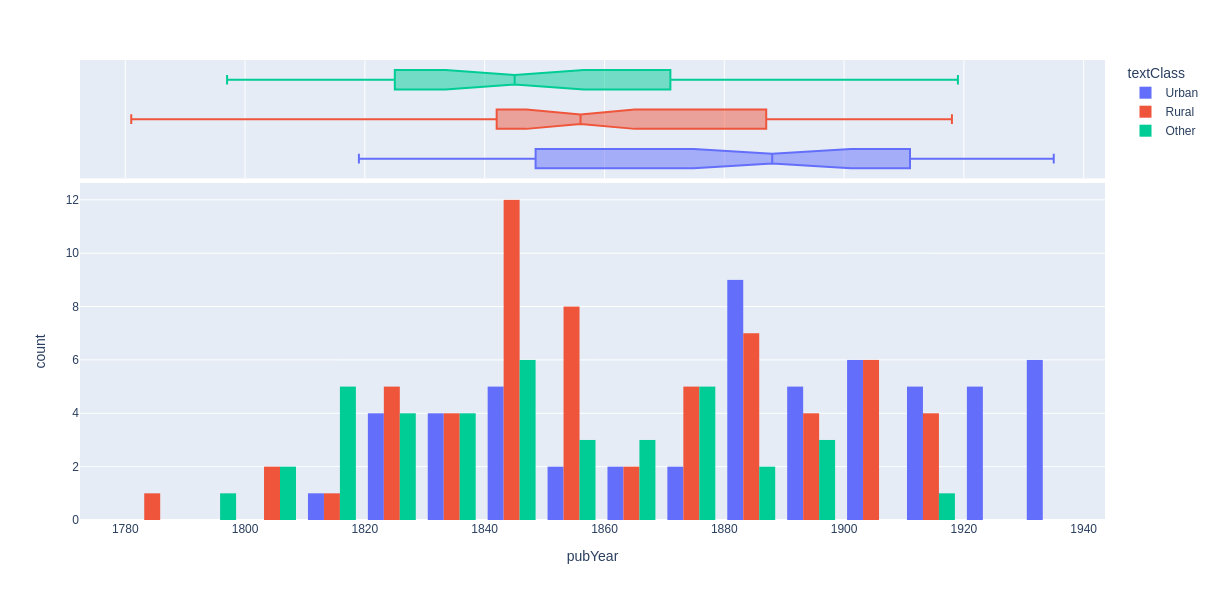

In [35]:
px.histogram(df, x="pubYear", color="textClass", barmode='group', marginal="box",height=600)

In [9]:
meta = pd.read_csv("../../GitHub/corpora-collection/sunset-corpus/metadata_updated-v2.csv")
meta.columns

Index(['filename', 'ID', 'title', 'gndID', 'author', 'birthYear', 'deathYear',
       'gender', 'nationality', 'pubYear', 'numTokens', 'timeslotPubYear',
       'timeslotBirthYear', 'source', 'n_chunks', 'textClass',
       'mean_prob_prose', 'mean_prob_drama', 'mean_prob_lyric',
       'corpusSubset'],
      dtype='str')

In [10]:
meta = meta.loc[meta.textClass=="prose"]

In [12]:
len(meta)

5692

In [15]:
meta.gender.value_counts()

gender
männlich    4917
weiblich     775
Name: count, dtype: int64

In [17]:
len(meta.author.unique())

702

In [18]:
meta.birthYear.min()

np.int64(1730)

In [19]:
meta.birthYear.max()

np.int64(1912)

In [14]:
meta.drop_duplicates(subset="author").gender.value_counts()

gender
männlich    564
weiblich    138
Name: count, dtype: int64

In [30]:
1/21

0.047619047619047616

In [33]:
meta.loc[~meta.pubYear.isna()]

,filename,ID,title,gndID,author,birthYear,deathYear,gender,nationality,pubYear,numTokens,timeslotPubYear,timeslotBirthYear,source,n_chunks,textClass,mean_prob_prose,mean_prob_drama,mean_prob_lyric,corpusSubset
1,kid30767.txt,1,Die Höhlenkinder – Im Pfahlbau,http://d-nb.info/gnd/119410885,A. Th. Sonnleitner,1869,1939,männlich,Tschechische Republik; Österreich,1918.0,45077.0,1910-1919,1860-1869,gb,180.0,prose,0.969230,0.019879,0.010891,wide
17,arnima_invalide_1818.txt,17,Der tolle Invalide auf dem Fort Ratonneau,http://d-nb.info/gnd/118504177,Achim von Arnim,1783,1833,männlich,Deutschland,1818.0,7955.0,1810-1819,1780-1789,https://www.deutschestextarchiv.de/book/show/a...,32.0,prose,0.946494,0.050992,0.002514,wide
18,Arnim_DerWintergarten_zeno.txt,18,Der Wintergarten,http://d-nb.info/gnd/118504177,Achim von Arnim,1784,1834,männlich,Deutschland,1809.0,102369.0,NaN,1780-1789,"http://www.zeno.org/Literatur/M/Arnim,+Ludwig+...",410.0,prose,0.780461,0.091525,0.128014,core
33,Arnim_FrauvonSaverne.txt,33,Frau von Saverne,http://d-nb.info/gnd/118504177,Achim von Arnim,1789,1839,männlich,Deutschland,1817.0,8069.0,1810-1819,1780-1789,https://www.projekt-gutenberg.org/arnim/savern...,32.0,prose,0.981916,0.017376,0.000708,wide
35,kid35132.txt,35,Holländische Liebhabereien,http://d-nb.info/gnd/118504177,Achim von Arnim,1781,1831,männlich,Deutschland,1826.0,15868.0,1820-1829,1780-1789,gb,64.0,prose,0.901720,0.059111,0.039169,wide
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6378,Benjamin_Einbahnstraße.txt,6381,Einbahnstraße,https://d-nb.info/gnd/118509039,Walter Benjamin,1892,1940,männlich,Deutschland; Frankreich; Schweiz,1928.0,NaN,NaN,NaN,https://de.wikisource.org/wiki/Einbahnstra%C3%9Fe,NaN,prose,NaN,NaN,NaN,core
6379,Schweizerbilder_Erster_Theil.txt,6382,"Schweizer Bilder, Erster Theil",https://d-nb.info/gnd/131405330,Jakob Frey,1824,1875,männlich,Deutschland; Schweiz,1869.0,NaN,NaN,NaN,https://projekt-gutenberg.org/authors/jakob-fr...,NaN,prose,NaN,NaN,NaN,core
6380,Gerstäcker_PfarrerUndSchule.txt,6383,Pfarrer und Schule,http://d-nb.info/gnd/118538810,Friedrich Gerstäcker,1816,1872,männlich,Deutschland,1849.0,NaN,NaN,NaN,https://www.gutenberg.org/cache/epub/46368/pg4...,NaN,prose,NaN,NaN,NaN,core
6381,Kinkel_Erzählungen.txt,6384,Erzählungen,http://d-nb.info/gnd/11856224X,Gottfried Kinkel,1815,1882,männlich,Deutschland; Schweiz,1849.0,NaN,NaN,NaN,NaN,NaN,prose,NaN,NaN,NaN,core


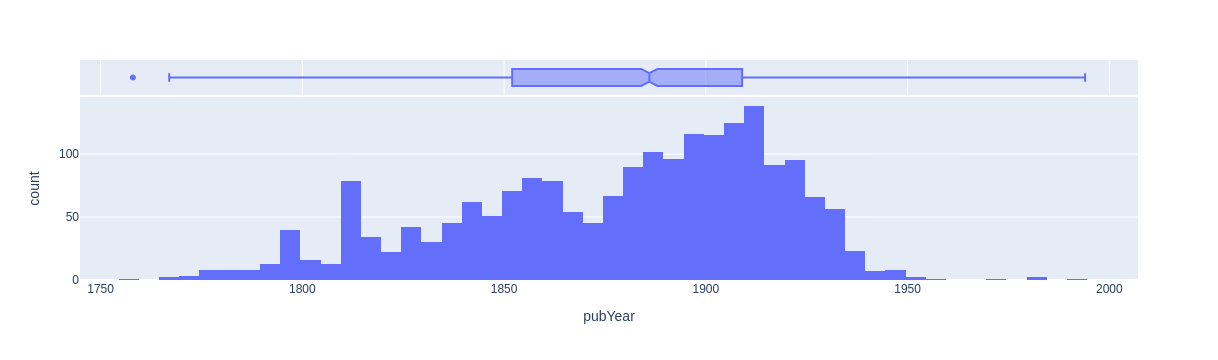

In [28]:
px.histogram(meta, x="pubYear", marginal="box")

In [29]:
n_tokens = 0
for file in meta.filename:
    with open("../../GitHub/corpora-collection/sunset-corpus/src/raw/"+file) as f:
        text = f.read()
    n_tokens=n_tokens +len(text.split())
n_tokens

227513212